# Lab Manual 11 — Text Visualization and Sentiment Analysis

## 1. Setup and load the data

In [11]:
import nltk
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to C:\Users\Shoaib Ali
[nltk_data]     Kori\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\Shoaib Ali
[nltk_data]     Kori\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [34]:


import re
import html
import warnings
from collections import Counter
from itertools import chain

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from wordcloud import WordCloud
from nltk.stem import PorterStemmer, WordNetLemmatizer
import nltk
from textblob import TextBlob

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 160)

from pathlib import Path
DATA_PATH = Path("Tweets.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("/mnt/data/Tweets.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place Tweets.csv in the same folder as this notebook.")
df = pd.read_csv(DATA_PATH)

required = {"text", "airline_sentiment", "airline", "tweet_created"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["text"] = df["text"].fillna("").astype(str)
df["airline_sentiment"] = df["airline_sentiment"].str.lower().str.strip()
df["tweet_created"] = pd.to_datetime(df["tweet_created"], errors="coerce", utc=True)

print("Rows and columns:", df.shape)
print("Missing values in key columns:")
display(df[["text", "airline_sentiment", "airline", "tweet_created"]].isna().sum())
display(df[["airline_sentiment", "airline"]].value_counts().head(10).rename("count").to_frame())

Rows and columns: (14640, 15)
Missing values in key columns:


text                 0
airline_sentiment    0
airline              0
tweet_created        0
dtype: int64

count
airline_sentiment airline          
negative          United       2633
                  US Airways   2263
                  American     1960
                  Southwest    1186
                  Delta         955
neutral           Delta         723
                  United        697
                  Southwest     664
positive          Southwest     570
                  Delta         544

## 2. Initial exploration

Sentiment labels:


,tweets
airline_sentiment,
negative,9178
neutral,3099
positive,2363


Airlines:


,tweets
airline,
United,3822
US Airways,2913
American,2759
Southwest,2420
Delta,2222
Virgin America,504


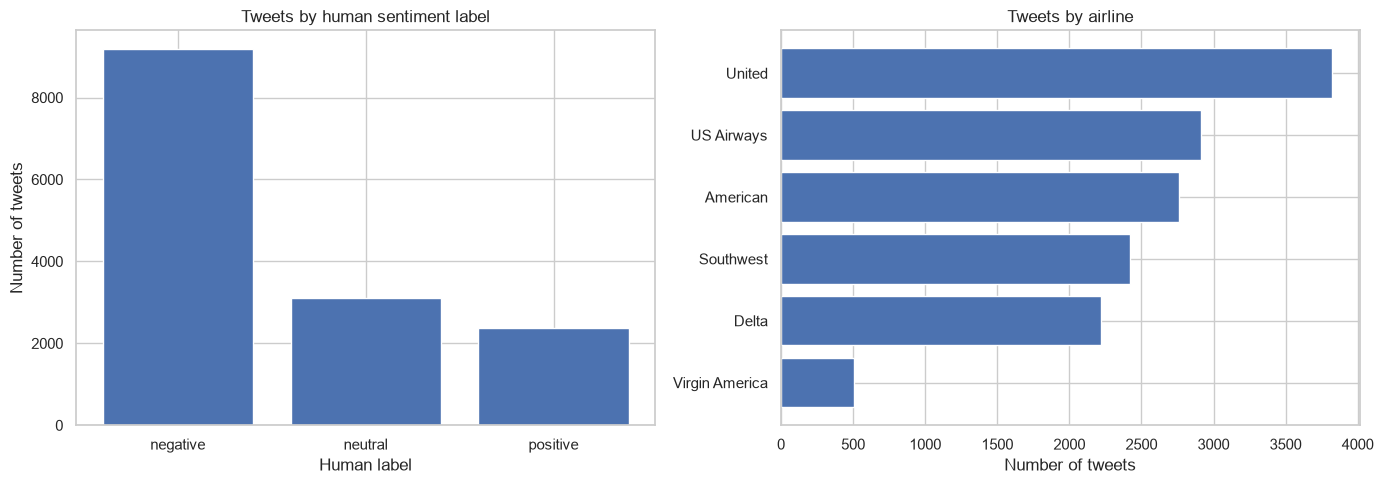

In [13]:
print("Sentiment labels:")
display(df["airline_sentiment"].value_counts().to_frame("tweets"))
print("Airlines:")
display(df["airline"].value_counts().to_frame("tweets"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sentiment_counts = df["airline_sentiment"].value_counts().reindex(["negative", "neutral", "positive"], fill_value=0)
axes[0].bar(sentiment_counts.index, sentiment_counts.values)
axes[0].set_title("Tweets by human sentiment label")
axes[0].set_xlabel("Human label")
axes[0].set_ylabel("Number of tweets")

airline_counts = df["airline"].value_counts()
axes[1].barh(airline_counts.index[::-1], airline_counts.values[::-1])
axes[1].set_title("Tweets by airline")
axes[1].set_xlabel("Number of tweets")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

## Part A — Tweet cleaning and preprocessing

### A1. Why a standard tokenizer struggles
Handles, hashtags, links, emojis and stretched spellings carry different information. The examples below compare a basic whitespace/punctuation tokenizer with the decisions used in this notebook:
- handles: remove the username, because it is usually not the complaint itself;
- URLs: replace with a URL marker during inspection, then remove from word-frequency analysis;
- hashtags: keep the hashtag word but remove `#`;
- emojis: remove from the main word analysis (this loses emotion; a future version could translate them);
- stretched words: reduce long repeated letters to two (for example, `sooooo` → `soo`).

In [14]:
sample_tweets = [
    "@airline this is sooooo bad!!!",
    "Thanks #greatservice 😊 https://example.com",
    "not happy with @support"
]

def naive_tokens(text):
    return re.findall(r"\b\w+\b", str(text).lower())

for t in sample_tweets:
    print("Tweet:     ", t)
    print("Naive:     ", naive_tokens(t))
    print()

Tweet:      @airline this is sooooo bad!!!
Naive:      ['airline', 'this', 'is', 'sooooo', 'bad']

Tweet:      Thanks #greatservice 😊 https://example.com
Naive:      ['thanks', 'greatservice', 'https', 'example', 'com']

Tweet:      not happy with @support
Naive:      ['not', 'happy', 'with', 'support']



### A2. Cleaning function and stop words
The default English stop-word list removes some negation words. We explicitly keep `no`, `nor`, and `not`, because removing them can reverse the meaning of a tweet.

In [15]:
NEGATIONS = {"no", "nor", "not"}
STOP_WORDS = set(ENGLISH_STOP_WORDS) - NEGATIONS
# Add only clear, low-information tokens. Airline names are handled separately below.
CUSTOM_STOP_WORDS = {"amp", "im", "ive", "id", "youre", "dont", "didnt", "doesnt", "cant", "wont"}

url_pattern = re.compile(r"https?://\S+|www\.\S+", flags=re.I)
mention_pattern = re.compile(r"@\w+")
hashtag_pattern = re.compile(r"#(\w+)")
stretch_pattern = re.compile(r"(\w)\1{2,}", flags=re.I)

def clean_text(text, remove_negations=False):
    text = html.unescape(str(text).lower())
    text = url_pattern.sub(" ", text)
    text = mention_pattern.sub(" ", text)
    text = hashtag_pattern.sub(r"\1", text)
    text = stretch_pattern.sub(lambda m: m.group(1) * 2, text)
    # Keep letters and spaces. This removes emoji and punctuation.
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = re.findall(r"[a-z]+", text)
    stop = STOP_WORDS | CUSTOM_STOP_WORDS
    if remove_negations:
        stop = stop | NEGATIONS
    return [w for w in tokens if w not in stop and len(w) > 1]

df["tokens"] = df["text"].apply(clean_text)
df["clean_text"] = df["tokens"].apply(" ".join)
df["tokens_without_negation"] = df["text"].apply(lambda x: clean_text(x, remove_negations=True))
df["clean_without_negation"] = df["tokens_without_negation"].apply(" ".join)

display(df[["text", "clean_text"]].head(8))

,text,clean_text
0,@VirginAmerica What @dhepburn said.,said
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus ve added commercials experience tacky
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,didn today mean need trip
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",really aggressive blast obnoxious entertainment guests faces little recourse
4,@VirginAmerica and it's a really big bad thing about it,really big bad thing
5,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's really the only bad thing about flying VA,seriously pay flight seats didn playing really bad thing flying va
6,"@VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)",yes nearly time fly vx ear worm won away
7,"@VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP",really missed prime opportunity men hats parody


In [16]:
# Demonstrate how removing negation changes the tokens and TextBlob polarity.
negation_examples = pd.DataFrame({
    "tweet": ["I am happy with the service", "I am not happy with the service",
              "The flight was good", "The flight was not good"],
})
negation_examples["with_negation"] = negation_examples["tweet"].apply(lambda x: " ".join(clean_text(x)))
negation_examples["without_negation"] = negation_examples["tweet"].apply(lambda x: " ".join(clean_text(x, remove_negations=True)))
negation_examples["polarity_original"] = negation_examples["tweet"].apply(lambda x: TextBlob(x).sentiment.polarity)
negation_examples["polarity_after_negation_removal"] = negation_examples["without_negation"].apply(lambda x: TextBlob(x).sentiment.polarity)
display(negation_examples)

,tweet,with_negation,without_negation,polarity_original,polarity_after_negation_removal
0,I am happy with the service,happy service,happy service,0.80,0.8
1,I am not happy with the service,not happy service,happy service,-0.40,0.8
2,The flight was good,flight good,flight good,0.70,0.7
3,The flight was not good,flight not good,flight good,-0.35,0.7


### A3. Stemming versus lemmatization
Stemming cuts word endings using rules; lemmatization aims to return a dictionary base form. We compare both on a sample vocabulary from the actual tweets. WordNet data is downloaded by NLTK if it is not already available.

In [17]:
try:
    nltk.data.find("corpora/wordnet")
    WORDNET_AVAILABLE = True
except LookupError:
    WORDNET_AVAILABLE = False

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def safe_lemma(word):
    if WORDNET_AVAILABLE:
        return lemmatizer.lemmatize(word)
    if word.endswith("ies") and len(word) > 4:
        return word[:-3] + "y"
    if word.endswith("s") and not word.endswith(("ss", "us")) and len(word) > 3:
        return word[:-1]
    return word

comparison_words = ["delayed", "delays", "cancelled", "cancellation", "flying",
                    "flight", "better", "worst", "services", "customers",
                    "running", "amazing", "was", "studies"]
comparison = pd.DataFrame({
    "word": comparison_words,
    "stem": [stemmer.stem(w) for w in comparison_words],
    "lemma_noun": [safe_lemma(w) for w in comparison_words],
    "lemma_verb": [lemmatizer.lemmatize(w, pos="v") if WORDNET_AVAILABLE else safe_lemma(w) for w in comparison_words],
})
display(comparison)

raw_vocab = len(set(chain.from_iterable(df["tokens"])))
stemmed_tokens = [[stemmer.stem(w) for w in row] for row in df["tokens"]]
lemmatized_tokens = [[safe_lemma(w) for w in row] for row in df["tokens"]]
stem_vocab = len(set(chain.from_iterable(stemmed_tokens)))
lemma_vocab = len(set(chain.from_iterable(lemmatized_tokens)))
print(f"Vocabulary sizes — cleaned: {raw_vocab:,}; stemmed: {stem_vocab:,}; lemmatized: {lemma_vocab:,}")


,word,stem,lemma_noun,lemma_verb
0,delayed,delay,delayed,delayed
1,delays,delay,delay,delay
2,cancelled,cancel,cancelled,cancelled
3,cancellation,cancel,cancellation,cancellation
4,flying,fli,flying,flying
5,flight,flight,flight,flight
6,better,better,better,better
7,worst,worst,worst,worst
8,services,servic,service,service
9,customers,custom,customer,customer


Vocabulary sizes — cleaned: 10,830; stemmed: 8,222; lemmatized: 9,878


### A4. Measure information lost at each cleaning stage

In [18]:
def stage_tokens(text, stage):
    x = html.unescape(str(text).lower())
    if stage >= 1:
        x = url_pattern.sub(" ", x)
        x = mention_pattern.sub(" ", x)
        x = hashtag_pattern.sub(r"\1", x)
    if stage >= 2:
        x = stretch_pattern.sub(lambda m: m.group(1) * 2, x)
        x = re.sub(r"[^a-z\s]", " ", x)
    toks = re.findall(r"[a-z]+", x)
    if stage >= 3:
        toks = [w for w in toks if w not in STOP_WORDS and w not in CUSTOM_STOP_WORDS and len(w) > 1]
    return toks

stages = []
for stage, label in [(0, "Raw lowercase tokens"), (1, "Remove handles and URLs; keep hashtag word"),
                     (2, "Normalize stretched words and remove punctuation/emoji"),
                     (3, "Remove stop words but keep negation")]:
    tok_rows = df["text"].apply(lambda x: stage_tokens(x, stage))
    all_tokens = list(chain.from_iterable(tok_rows))
    stages.append({
        "stage": label,
        "vocabulary_size": len(set(all_tokens)),
        "mean_tweet_length": np.mean([len(x) for x in tok_rows]),
        "tweets_empty": sum(len(x) == 0 for x in tok_rows)
    })
stage_table = pd.DataFrame(stages)
display(stage_table)

,stage,vocabulary_size,mean_tweet_length,tweets_empty
0,Raw lowercase tokens,13660,17.969194,0
1,Remove handles and URLs; keep hashtag word,11175,16.412295,0
2,Normalize stretched words and remove punctuation/emoji,11142,16.412295,0
3,Remove stop words but keep negation,10830,7.958880,49


**Decision:** Keep negations and hashtag words. Remove handles and links because they usually add noise to topic counts. Normalize stretched words rather than deleting them. Stemming is useful for reducing vocabulary, but it can create unreadable stems; for this business-facing analysis, cleaned words and light lemmatization are easier to interpret.

## Part B — Word frequency, TF-IDF and phrases

### B5. Raw word frequency and airline-name dominance
First show the unfiltered top words. Then remove airline names (and their common token forms) to expose customer topics. Airline-name dominance is consistent with tweets being addressed to or mentioning airline accounts; it does not mean those names are the main complaint.

,count
to,8652
i,6703
the,6061
a,4514
you,4401
united,4164
for,3999
flight,3939
on,3815
and,3733


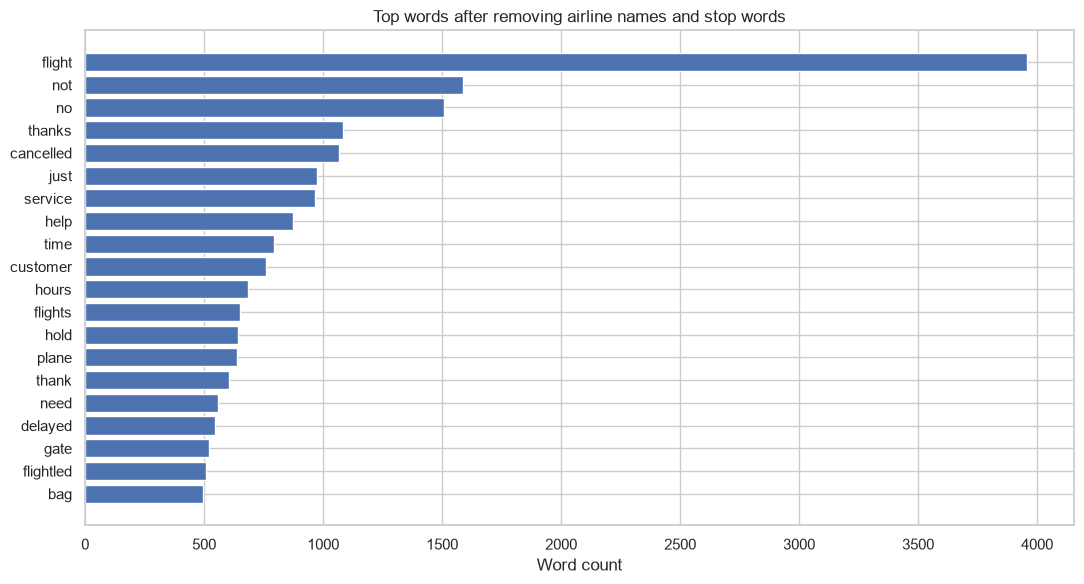

In [19]:
raw_all = list(chain.from_iterable(df["text"].apply(naive_tokens)))
raw_top = pd.Series(Counter(raw_all)).sort_values(ascending=False).head(15)
display(raw_top.rename("count").to_frame())

airline_terms = set()
for airline in df["airline"].dropna().unique():
    airline_terms.update(re.findall(r"[a-z]+", airline.lower()))
topic_tokens = df["tokens"].apply(lambda row: [w for w in row if w not in airline_terms])
topic_counts = Counter(chain.from_iterable(topic_tokens))
top_topic = pd.Series(topic_counts).sort_values(ascending=False).head(20)

plt.figure(figsize=(11, 6))
plt.barh(top_topic.index[::-1], top_topic.values[::-1])
plt.title("Top words after removing airline names and stop words")
plt.xlabel("Word count")
plt.ylabel("")
plt.tight_layout()
plt.show()

### B6. Words that distinguish positive and negative tweets (TF-IDF)

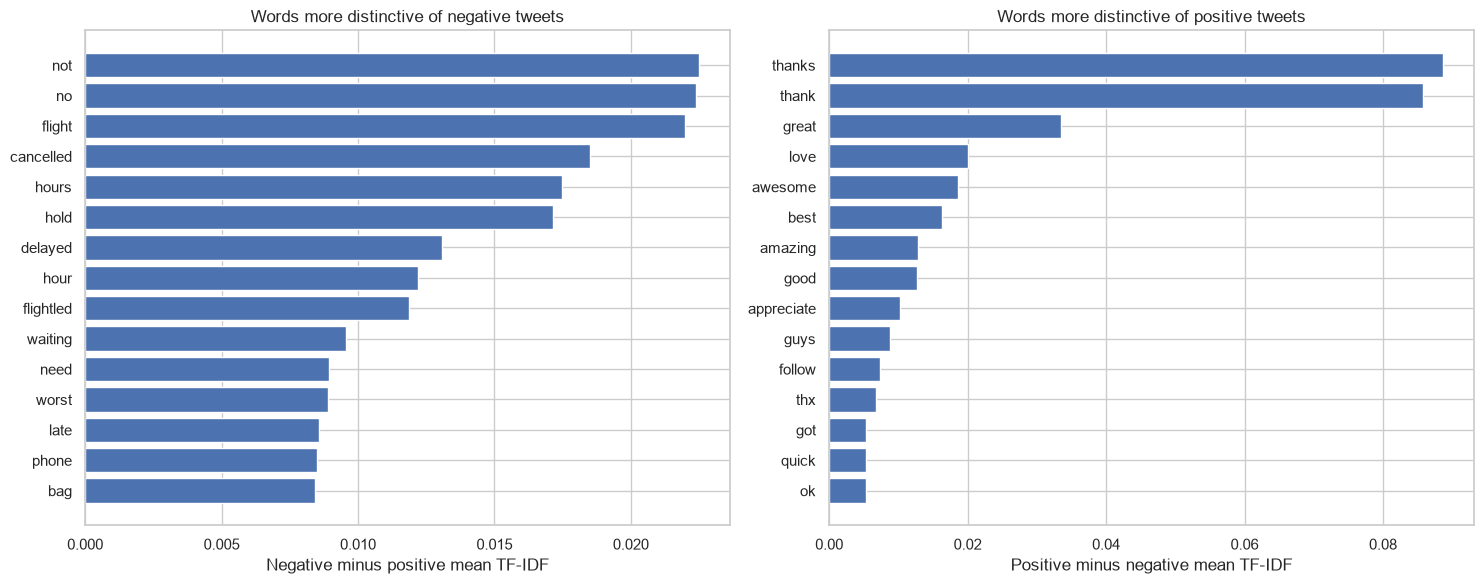

,word,negative_tfidf,positive_tfidf,difference
1344,not,0.028783,0.006276,0.022507
1335,no,0.028202,0.005831,0.022370
778,flight,0.048537,0.026538,0.021999
270,cancelled,0.021871,0.003380,0.018491
974,hours,0.018186,0.000704,0.017482
952,hold,0.018040,0.000897,0.017143
514,delayed,0.014829,0.001737,0.013092
973,hour,0.013807,0.001614,0.012192
786,flightled,0.013188,0.001330,0.011859
2139,waiting,0.011085,0.001518,0.009567


In [20]:
# Fit TF-IDF on individual tweets, then average scores within each sentiment class.
sentiment_docs = df.loc[df["airline_sentiment"].isin(["negative", "positive"]), ["clean_text", "airline_sentiment"]].copy()
tfidf = TfidfVectorizer(ngram_range=(1, 1), min_df=5, max_features=5000)
X = tfidf.fit_transform(sentiment_docs["clean_text"])
terms = np.array(tfidf.get_feature_names_out())
negative_scores = np.asarray(X[sentiment_docs["airline_sentiment"].eq("negative").values].mean(axis=0)).ravel()
positive_scores = np.asarray(X[sentiment_docs["airline_sentiment"].eq("positive").values].mean(axis=0)).ravel()
tfidf_diff = pd.DataFrame({"word": terms, "negative_tfidf": negative_scores, "positive_tfidf": positive_scores})
tfidf_diff["difference"] = tfidf_diff["negative_tfidf"] - tfidf_diff["positive_tfidf"]
top_neg_tfidf = tfidf_diff.nlargest(15, "difference").sort_values("difference")
top_pos_tfidf = tfidf_diff.nsmallest(15, "difference").sort_values("difference", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(top_neg_tfidf["word"], top_neg_tfidf["difference"])
axes[0].set_title("Words more distinctive of negative tweets")
axes[0].set_xlabel("Negative minus positive mean TF-IDF")
axes[1].barh(top_pos_tfidf["word"], -top_pos_tfidf["difference"])
axes[1].set_title("Words more distinctive of positive tweets")
axes[1].set_xlabel("Positive minus negative mean TF-IDF")
plt.tight_layout()
plt.show()
display(tfidf_diff.sort_values("difference", ascending=False).head(10))


### B6. Butterfly chart: positive versus negative vocabulary
This back-to-back chart compares the most distinctive words in the two groups. Bars extend in opposite directions so the group difference is easy to see.

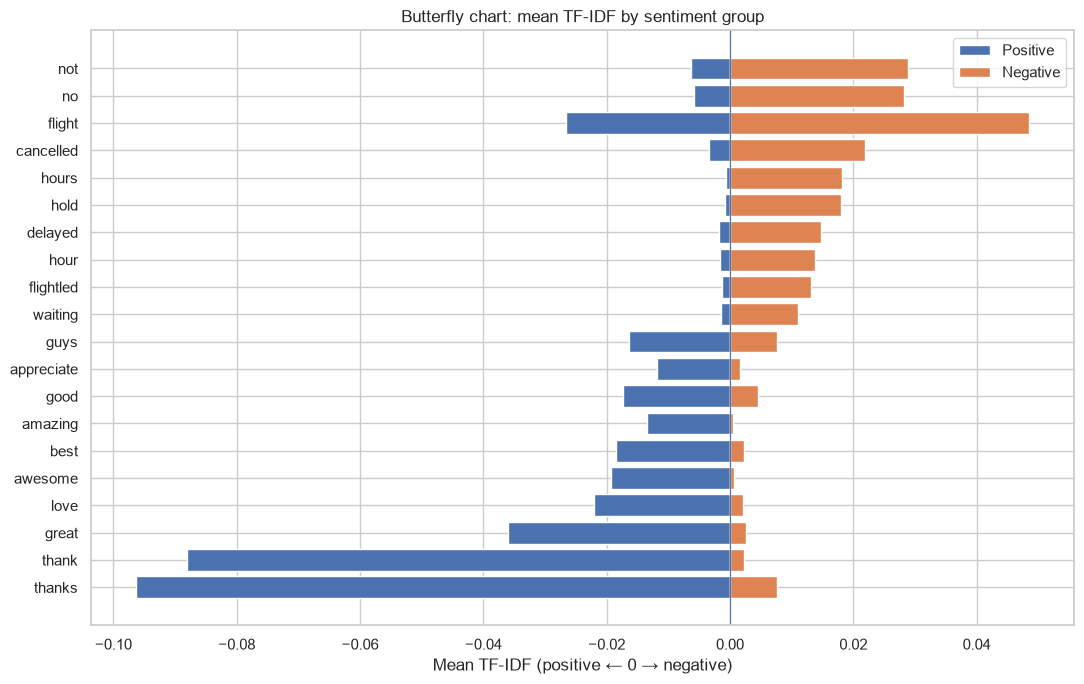

In [21]:
# Select the ten strongest distinctive terms on each side.
butterfly_terms = pd.concat([
    tfidf_diff.nlargest(10, "difference"),
    tfidf_diff.nsmallest(10, "difference")
]).drop_duplicates("word")
butterfly_terms = butterfly_terms.sort_values("difference")
y = np.arange(len(butterfly_terms))
plt.figure(figsize=(11, 7))
plt.barh(y, -butterfly_terms["positive_tfidf"], label="Positive")
plt.barh(y, butterfly_terms["negative_tfidf"], label="Negative")
plt.yticks(y, butterfly_terms["word"])
plt.axvline(0, linewidth=0.8)
plt.title("Butterfly chart: mean TF-IDF by sentiment group")
plt.xlabel("Mean TF-IDF (positive ← 0 → negative)")
plt.legend()
plt.tight_layout()
plt.show()

### B7. Bigram and trigram charts for negative tweets

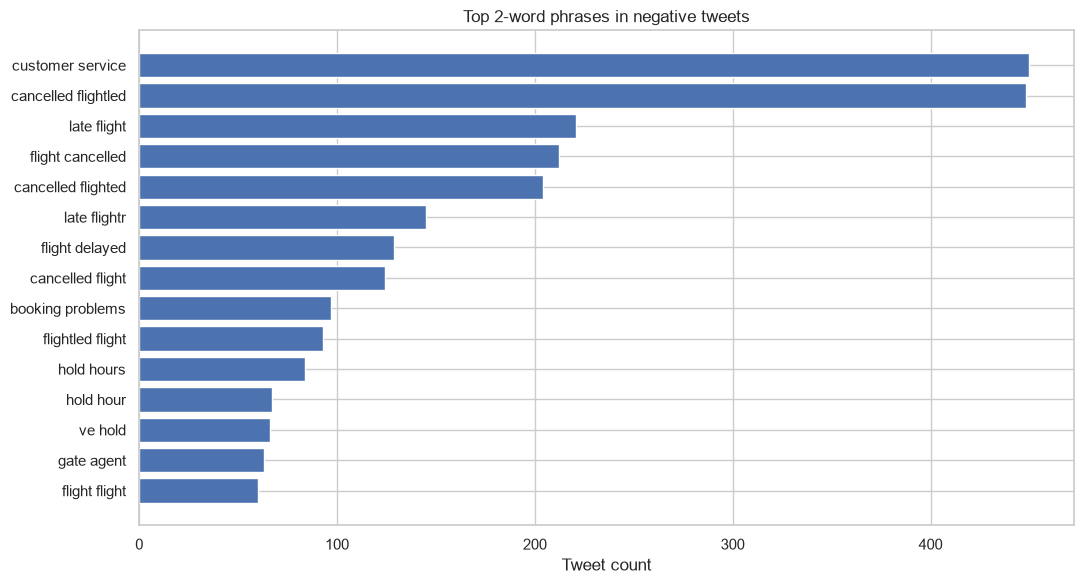

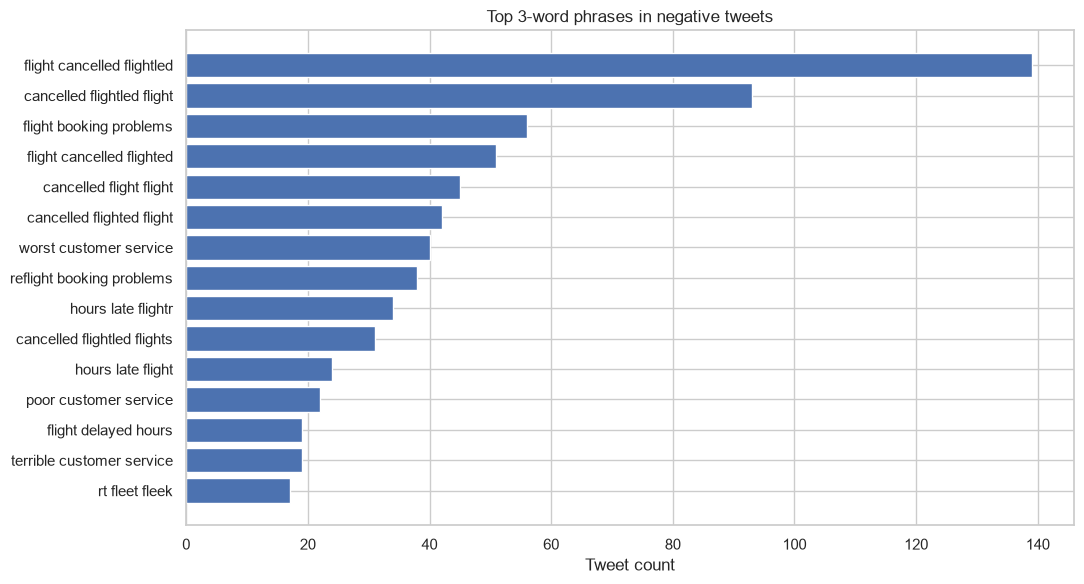

,count
customer service,450
cancelled flightled,448
late flight,221
flight cancelled,212
cancelled flighted,204
late flightr,145
flight delayed,129
cancelled flight,124
booking problems,97
flightled flight,93


,count
flight cancelled flightled,139
cancelled flightled flight,93
flight booking problems,56
flight cancelled flighted,51
cancelled flight flight,45
cancelled flighted flight,42
worst customer service,40
reflight booking problems,38
hours late flightr,34
cancelled flightled flights,31


"not good" bigram count in negative tweets: 0
"not great" bigram count in negative tweets: 0
"no good" bigram count in negative tweets: 0


,airline_sentiment,text


In [22]:
negative_docs = df.loc[df["airline_sentiment"] == "negative", "clean_text"]
def plot_ngrams(docs, n, top_n=15):
    vectorizer = CountVectorizer(ngram_range=(n, n), min_df=3)
    matrix = vectorizer.fit_transform(docs)
    counts = np.asarray(matrix.sum(axis=0)).ravel()
    names = vectorizer.get_feature_names_out()
    result = pd.Series(counts, index=names).sort_values(ascending=False).head(top_n)
    plt.figure(figsize=(11, 6))
    plt.barh(result.index[::-1], result.values[::-1])
    plt.title(f"Top {n}-word phrases in negative tweets")
    plt.xlabel("Tweet count")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()
    return result

top_bigrams = plot_ngrams(negative_docs, 2)
top_trigrams = plot_ngrams(negative_docs, 3)
display(top_bigrams.head(10).to_frame("count"))
display(top_trigrams.head(10).to_frame("count"))
# A phrase can reverse the meaning suggested by an individual word.
for phrase in ["not good", "not great", "no good"]:
    phrase_count = int(top_bigrams.get(phrase, 0))
    print(f'"{phrase}" bigram count in negative tweets: {phrase_count}')
phrase_examples = df[df["text"].str.contains(r"\\bnot good\\b", case=False, regex=True, na=False)][
    ["airline_sentiment", "text"]
].head(5)
display(phrase_examples)


### B8. Word cloud versus frequency bar chart

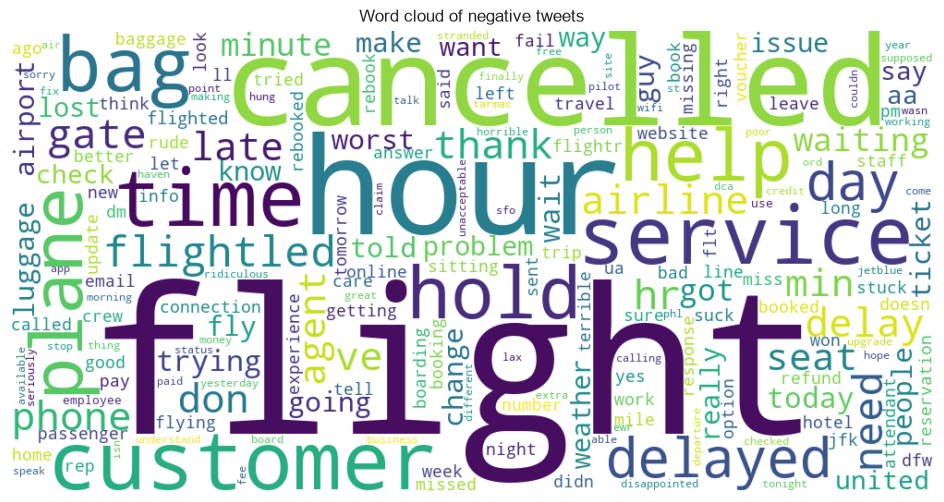

In [23]:
negative_words = " ".join(df.loc[df["airline_sentiment"] == "negative", "clean_text"])
if negative_words.strip():
    wc = WordCloud(width=1000, height=500, background_color="white", collocations=False).generate(negative_words)
    plt.figure(figsize=(13, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word cloud of negative tweets")
    plt.show()

# The frequency bar chart is better for the Director because exact counts are readable.

**Director-facing choice:** Use the bar chart as the main evidence because it shows exact counts and supports comparison. The word cloud is a quick visual overview, but font size and layout make precise comparisons difficult.

## Part C — Automated sentiment versus human labels

TextBlob polarity is used as the lexicon-based sentiment tool. It is a simple baseline, not a trained airline-specific classifier. Neutral thresholds are stated explicitly below.

Overall accuracy: 0.4507
              precision    recall  f1-score   support

    negative       0.89      0.32      0.47      9178
     neutral       0.30      0.60      0.40      3099
    positive       0.35      0.76      0.48      2363

    accuracy                           0.45     14640
   macro avg       0.51      0.56      0.45     14640
weighted avg       0.68      0.45      0.46     14640



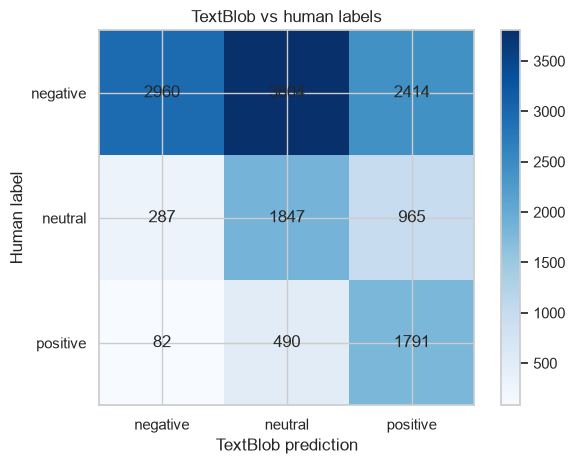

In [24]:
def textblob_label(text):
    score = TextBlob(str(text)).sentiment.polarity
    if score > 0.05:
        return "positive"
    if score < -0.05:
        return "negative"
    return "neutral"

df["textblob_polarity"] = df["text"].apply(lambda x: TextBlob(x).sentiment.polarity)
df["textblob_sentiment"] = df["textblob_polarity"].apply(
    lambda s: "positive" if s > 0.05 else ("negative" if s < -0.05 else "neutral")
)

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
valid = df["airline_sentiment"].isin(["positive", "neutral", "negative"])
y_true = df.loc[valid, "airline_sentiment"]
y_pred = df.loc[valid, "textblob_sentiment"]
print("Overall accuracy:", round(accuracy_score(y_true, y_pred), 4))
print(classification_report(y_true, y_pred, labels=["negative", "neutral", "positive"], zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=["negative", "neutral", "positive"])
plt.imshow(cm, cmap="Blues")
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, str(value), ha="center", va="center")
plt.xticks(range(3), ["negative", "neutral", "positive"])
plt.yticks(range(3), ["negative", "neutral", "positive"])
plt.colorbar()
plt.title("TextBlob vs human labels")
plt.xlabel("TextBlob prediction")
plt.ylabel("Human label")
plt.tight_layout()
plt.show()

### C10. Largest disagreement groups and examples

In [25]:
df["disagreement"] = valid & (df["airline_sentiment"] != df["textblob_sentiment"])

def disagreement_cause(text):
    t = str(text).lower()
    if re.search(r"\b(not|no|never|n't)\b", t):
        return "Negation"
    if re.search(r"\b(lol|haha|yeah right|great job|thanks for nothing|love being)\b", t):
        return "Possible sarcasm"
    if re.search(r"\b(but|however|although|though)\b", t):
        return "Mixed feelings"
    if re.search(r"\b(delayed|delay|cancelled|canceled|lost|luggage|bag|wait|stuck)\b", t):
        return "Airline operational language"
    return "Other / context or lexicon gap"

disagreements = df.loc[df["disagreement"]].copy()
disagreements["cause"] = disagreements["text"].apply(disagreement_cause)
cause_counts = disagreements["cause"].value_counts()
display(cause_counts.to_frame("disagreements"))
display(disagreements.sort_values("textblob_polarity").head(8)[
    ["airline", "airline_sentiment", "textblob_sentiment", "textblob_polarity", "text"]
])

,disagreements
cause,
Other / context or lexicon gap,4311
Negation,1826
Airline operational language,1265
Mixed feelings,572
Possible sarcasm,68


,airline,airline_sentiment,textblob_sentiment,textblob_polarity,text
951,United,neutral,negative,-1.000,"@united yes, after this awful weather it appears I can get home"
5626,Southwest,neutral,negative,-1.000,@SouthwestAir I can go. I want to badly!!!! I don't know how to DM. Can I e-mail you? Help!!! wmn4life@hotmail.com
10416,US Airways,neutral,negative,-1.000,@USAirways I should also add the weather conditions are terrible. Expecting 18 inches of snow. Any advice?
10895,US Airways,positive,negative,-1.000,@USAirways made it!!! Send Bloody Mary's to row 27!!!
8341,Delta,neutral,negative,-1.000,@JetBlue Ever consider coming to Memphis? Need some TrueBlue service and fares badly!!
8224,Delta,positive,negative,-0.910,"@JetBlue yes thankfully! Catering just got here and now they are loading, but very frustrated. I was supposed to be there by 10-10:30"
9011,US Airways,neutral,negative,-0.875,@USAirways any travel advisory coming for the Carolinas? Bad weather!
12206,American,neutral,negative,-0.750,"@AmericanAir @dfwairport That's DFW!? OMG! Yeah cold, everywhere!"


### C11. Three purpose-built test tweets

In [26]:
test_tweets = [
    "Great, another flight delay. Just what I needed.",
    "I am not unhappy with the helpful crew.",
    "The food was good, but the flight was cancelled and my bags are missing."
]
test_results = pd.DataFrame({"tweet": test_tweets})
test_results["polarity"] = test_results["tweet"].apply(lambda x: TextBlob(x).sentiment.polarity)
test_results["tool_label"] = test_results["polarity"].apply(
    lambda s: "positive" if s > 0.05 else ("negative" if s < -0.05 else "neutral")
)
display(test_results)

,tweet,polarity,tool_label
0,"Great, another flight delay. Just what I needed.",0.80,positive
1,I am not unhappy with the helpful crew.,0.30,positive
2,"The food was good, but the flight was cancelled and my bags are missing.",0.25,positive


### C12. High-confidence human labels

In [27]:
if "airline_sentiment_confidence" in df.columns:
    confidence = pd.to_numeric(df["airline_sentiment_confidence"], errors="coerce")
    confidence_results = []
    for threshold in [0.0, 0.7, 0.8, 0.9]:
        keep = valid & (confidence >= threshold)
        confidence_results.append({
            "minimum_human_confidence": threshold,
            "tweets_kept": int(keep.sum()),
            "coverage": keep.mean(),
            "accuracy": accuracy_score(df.loc[keep, "airline_sentiment"],
                                       df.loc[keep, "textblob_sentiment"]) if keep.sum() else np.nan
        })
    display(pd.DataFrame(confidence_results))
else:
    print("No airline_sentiment_confidence column is available.")

,minimum_human_confidence,tweets_kept,coverage,accuracy
0,0.0,14640,1.000000,0.450683
1,0.7,10768,0.735519,0.461924
2,0.8,10459,0.714413,0.463907
3,0.9,10458,0.714344,0.463855


**Interpretation:** Overall accuracy alone can hide class imbalance and different performance by class. Read the confusion matrix and per-class precision/recall. The tool should support triage, not replace human review: sarcasm, negation, mixed opinions and airline-specific operational terms need context.

## Part D — Airline comparison and action priorities

### D13–14. Complaint mix and sentiment share
Compare within-airline percentages, not only raw counts, because airlines have different tweet volumes.

airline_sentiment,negative,neutral,positive
airline,,,
American,1960,463,336
Delta,955,723,544
Southwest,1186,664,570
US Airways,2263,381,269
United,2633,697,492
Virgin America,181,171,152


airline_sentiment,negative,neutral,positive
airline,,,
American,71.0,16.8,12.2
Delta,43.0,32.5,24.5
Southwest,49.0,27.4,23.6
US Airways,77.7,13.1,9.2
United,68.9,18.2,12.9
Virgin America,35.9,33.9,30.2


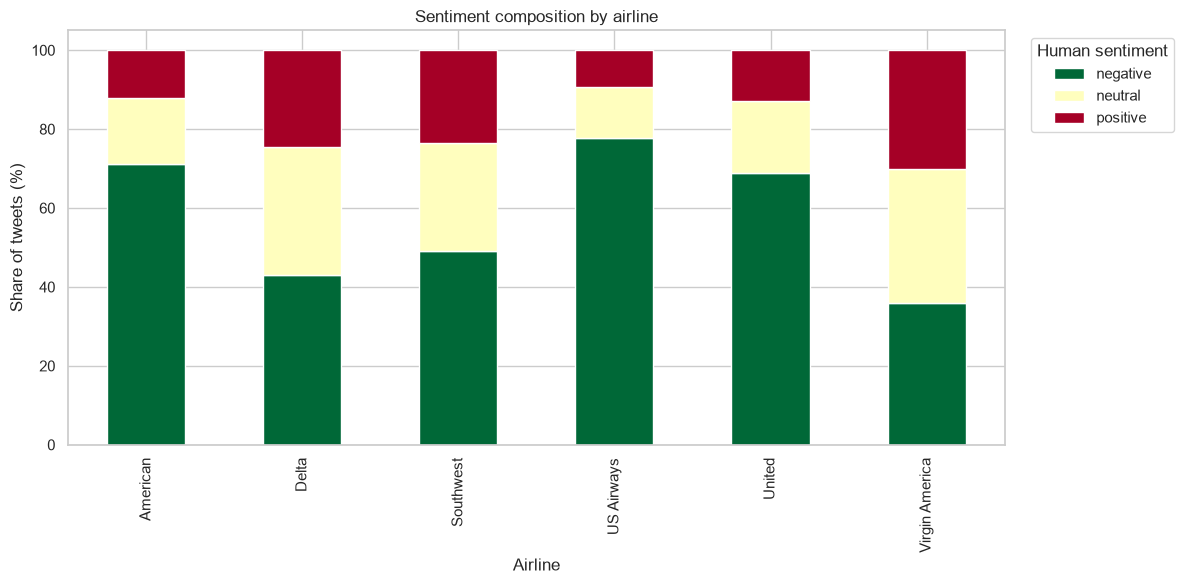

,total_tweets,negative_tweets,negative_share_pct
airline,,,
US Airways,2913,2263,77.7
American,2759,1960,71.0
United,3822,2633,68.9
Southwest,2420,1186,49.0
Delta,2222,955,43.0
Virgin America,504,181,35.9


In [28]:
sentiment_counts = pd.crosstab(df["airline"], df["airline_sentiment"])
sentiment_share = pd.crosstab(df["airline"], df["airline_sentiment"], normalize="index") * 100
display(sentiment_counts)
display(sentiment_share.round(1))

sentiment_share[["negative", "neutral", "positive"]].plot(
    kind="bar", stacked=True, figsize=(12, 6), colormap="RdYlGn_r"
)
plt.title("Sentiment composition by airline")
plt.xlabel("Airline")
plt.ylabel("Share of tweets (%)")
plt.legend(title="Human sentiment", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

airline_summary = pd.DataFrame({
    "total_tweets": df.groupby("airline").size(),
    "negative_tweets": df[df["airline_sentiment"] == "negative"].groupby("airline").size(),
    "negative_share_pct": df.assign(is_negative=df["airline_sentiment"].eq("negative"))
                             .groupby("airline")["is_negative"].mean() * 100
}).fillna(0).sort_values("negative_share_pct", ascending=False)
display(airline_summary.round(1))

### D13. What are the negative tweets about for each airline?

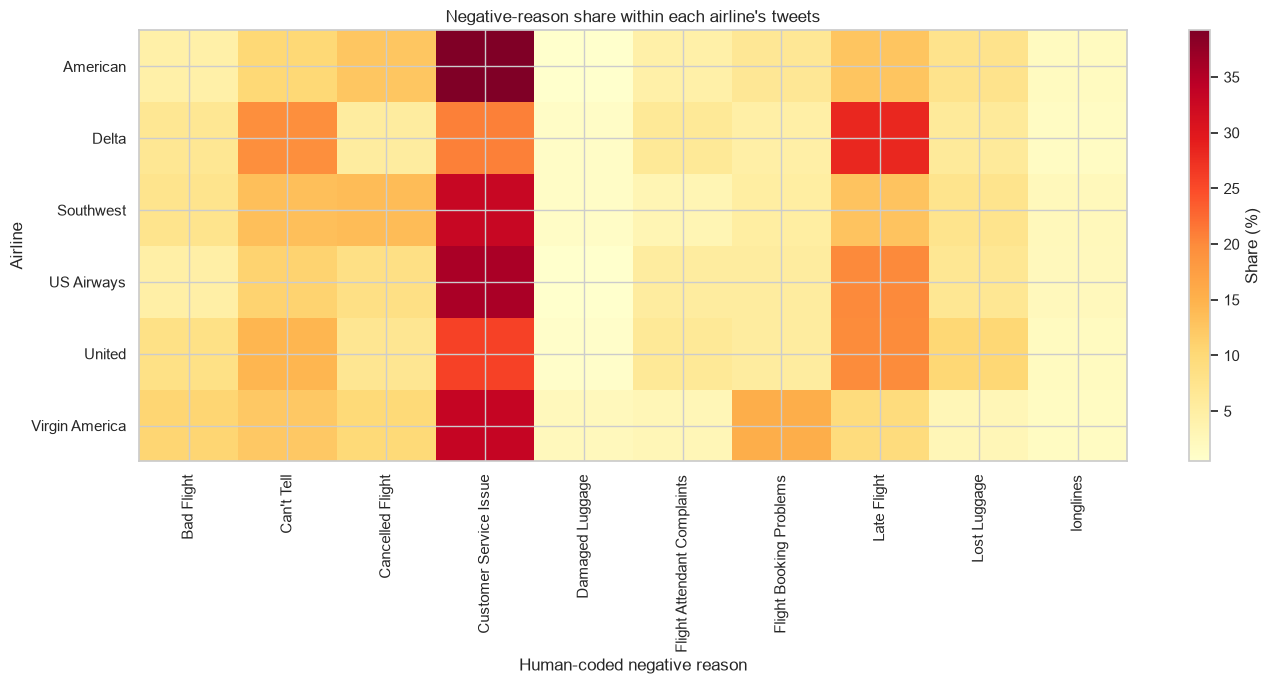

,negative tweets
negativereason,
Customer Service Issue,2910
Late Flight,1665
Can't Tell,1190
Cancelled Flight,847
Lost Luggage,724
Bad Flight,580
Flight Booking Problems,529
Flight Attendant Complaints,481
longlines,178


In [29]:
if "negativereason" in df.columns:
    reason_mix = pd.crosstab(df["airline"], df["negativereason"], normalize="index") * 100
    plt.figure(figsize=(14, 7))
    plt.imshow(reason_mix.values, aspect="auto", cmap="YlOrRd")
    plt.xticks(range(len(reason_mix.columns)), reason_mix.columns, rotation=90)
    plt.yticks(range(len(reason_mix.index)), reason_mix.index)
    plt.colorbar(label="Share (%)")
    plt.title("Negative-reason share within each airline's tweets")
    plt.xlabel("Human-coded negative reason")
    plt.ylabel("Airline")
    plt.tight_layout()
    plt.show()
    display(df.loc[df["airline_sentiment"] == "negative", "negativereason"].value_counts().to_frame("negative tweets"))


### D15. Negative sentiment over time

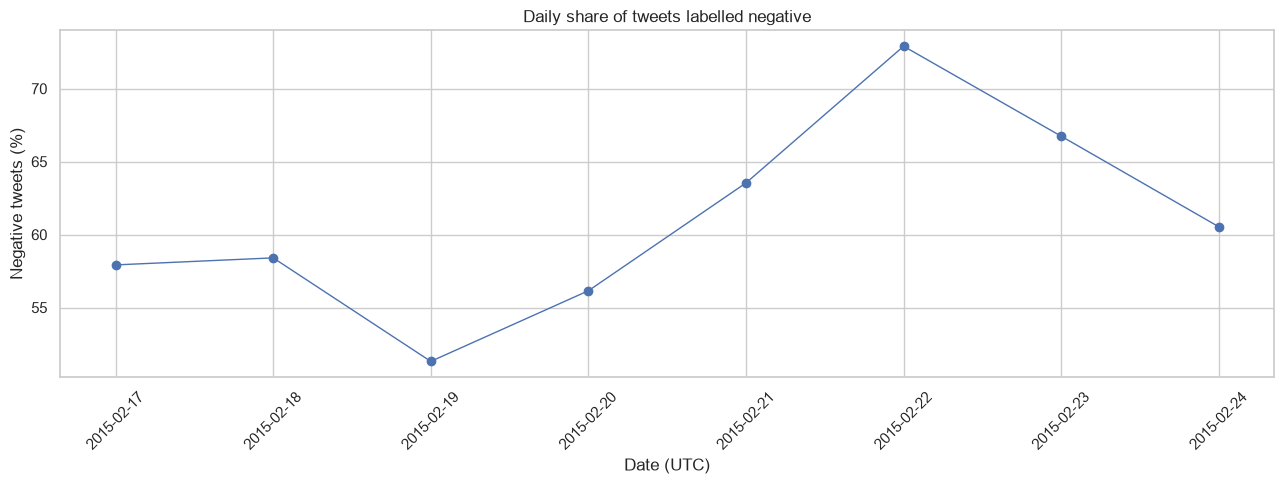

,total_tweets,negative_tweets,negative_share_pct
tweet_created,,,
2015-02-22 00:00:00+00:00,2392,1744,72.909699
2015-02-23 00:00:00+00:00,3515,2346,66.742532
2015-02-21 00:00:00+00:00,1418,901,63.540197
2015-02-24 00:00:00+00:00,2136,1293,60.533708
2015-02-18 00:00:00+00:00,1416,827,58.403955


In [30]:
daily = df.dropna(subset=["tweet_created"]).set_index("tweet_created").groupby(pd.Grouper(freq="D")).agg(
    total_tweets=("airline_sentiment", "size"),
    negative_tweets=("airline_sentiment", lambda x: (x == "negative").sum())
)
daily["negative_share_pct"] = daily["negative_tweets"] / daily["total_tweets"] * 100
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(daily.index, daily["negative_share_pct"], marker="o", linewidth=1)
ax.set_title("Daily share of tweets labelled negative")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Negative tweets (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
display(daily.sort_values("negative_share_pct", ascending=False).head(5))

### D16. A practical response-priority rule

In [31]:
# A transparent triage score using only fields in this dataset:
# 1) negative human label, 2) negative-label confidence, 3) retweet count as a rough visibility signal.
df["retweet_count"] = pd.to_numeric(df["retweet_count"], errors="coerce").fillna(0)
df["airline_sentiment_confidence"] = pd.to_numeric(df["airline_sentiment_confidence"], errors="coerce")
retweet_cap = max(float(df["retweet_count"].quantile(0.95)), 1)
df["visibility_score"] = np.minimum(df["retweet_count"], retweet_cap) / retweet_cap
df["priority_score"] = np.where(
    df["airline_sentiment"].eq("negative"),
    0.7 * df["airline_sentiment_confidence"].fillna(0) + 0.3 * df["visibility_score"],
    0
)
priority = df.loc[df["airline_sentiment"] == "negative"].sort_values("priority_score", ascending=False)
display(priority[["airline", "airline_sentiment_confidence", "retweet_count", "negativereason",
                 "priority_score", "text"]].head(15))

,airline,airline_sentiment_confidence,retweet_count,negativereason,priority_score,text
2882,United,1.0,1,Late Flight,1.0,@united I booked and paid for a flight to get me to Denver at a specific time for a meeting. You failed... It wasn't caused by weather
2226,United,1.0,1,Customer Service Issue,1.0,@united I sent a PM over two weeks ago and have heard nothing! #horribleservice #unitedsucks
2918,United,1.0,1,Bad Flight,1.0,@united the new seats on the Canadaair regional jets just plain suck.
1437,United,1.0,1,Late Flight,1.0,"@united A very disappointing experience - plane mech. delay and next one didn't wait. No sincere apology, just told me to complain online"
2188,United,1.0,1,Cancelled Flight,1.0,"@United - flight Cancelled Flightled. 4 hrs at airport to book a new one for $95. Just got two invoices for the flight, each for approx $300. Really?!"
2189,United,1.0,1,Flight Attendant Complaints,1.0,@united why do you hire POS pilots? Thanks for ruining my trip and not allowing me to see my buddy as he turns 30. #unitedsucksdick
2190,United,1.0,3,Customer Service Issue,1.0,.@united Your airline is again rated the WORST in America so you've got your work cut out for you. It's bc you treat customers like garbage.
866,United,1.0,1,Bad Flight,1.0,"@united is horrible!! They lost our carseat and expect us to use a loner carseat, safety regulations say it's illegal to use a used car seat"
870,United,1.0,1,Flight Booking Problems,1.0,"@united: I don't care that a @thehipmunk link showed me a ""wrong"" price on your site—it's your site &amp; responsibility to ensure correctness."
2276,United,1.0,1,Can't Tell,1.0,@united We've let you know how to help the millions of customers you've treated like garbage. It's no coincidence ur ranked WORST airline.


**Triage rule:** First review negative tweets with high human-label confidence and higher retweet counts. Retweets are only a visibility proxy, not proof of reach or passenger harm. A real response team should also add operational severity and whether the issue is still unresolved; those fields are not present here.

## Part E — Limitations and recommendation

1. **Selection bias:** people who post on Twitter are not all passengers; people with strong experiences may post more.
2. **Platform bias:** users of Twitter in 2015 may differ from today's customers and from customers using other channels.
3. **Language/context bias:** short text, slang, sarcasm, spelling and missing conversation context can mislead both humans and software.
4. **Coverage bias:** this file covers a short period in February 2015, not a full year or today's operations.
5. **Label uncertainty:** human sentiment labels have confidence scores and may not represent perfect ground truth.

Findings that are likely to change today include airline service channels, common complaint topics, language, platform usage and operational conditions. The data can identify patterns in this sample, but it cannot establish why a spike occurred or represent all passengers.

## Part F — Three additional decision-useful insights

,retweet_count
count,14640.000000
mean,0.082650
std,0.745778
min,0.000000
50%,0.000000
90%,0.000000
95%,1.000000
99%,1.000000
max,44.000000


,count,mean,median
airline_sentiment,,,
negative,9178,20.39,22.0
neutral,3099,15.29,15.0
positive,2363,14.48,14.0


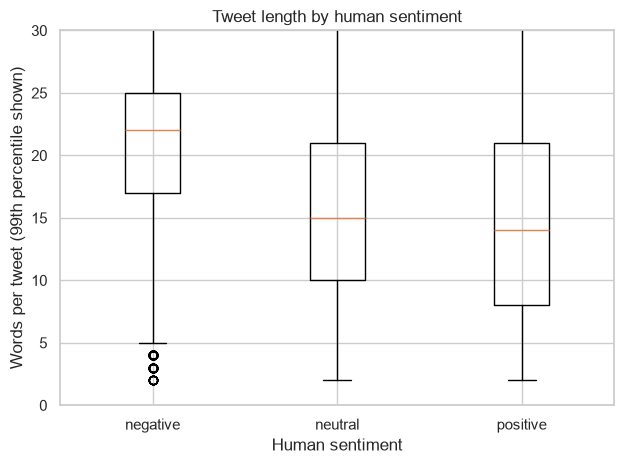

,most_common_negative_reason,count
airline,,
US Airways,Customer Service Issue,811
American,Customer Service Issue,768
United,Customer Service Issue,681
Southwest,Customer Service Issue,391
Delta,Late Flight,269
Virgin America,Customer Service Issue,60


In [33]:
# Additional insight 1: Retweet distribution
df["retweet_count"] = pd.to_numeric(df["retweet_count"], errors="coerce")

retweet_summary = df["retweet_count"].describe(
    percentiles=[.5, .9, .95, .99]
).to_frame("retweet_count")

display(retweet_summary)


# Additional insight 2: Tweet length by human sentiment
df["raw_word_count"] = df["text"].fillna("").str.findall(r"\b\w+\b").str.len()

length_summary = df.groupby("airline_sentiment")["raw_word_count"].agg(
    ["count", "mean", "median"]
).round(2)

display(length_summary)

sentiments = ["negative", "neutral", "positive"]

length_groups = [
    df.loc[df["airline_sentiment"] == label, "raw_word_count"]
    for label in sentiments
]

plt.boxplot(length_groups)
plt.xticks([1, 2, 3], sentiments)
plt.ylim(0, df["raw_word_count"].quantile(.99))
plt.title("Tweet length by human sentiment")
plt.xlabel("Human sentiment")
plt.ylabel("Words per tweet (99th percentile shown)")
plt.tight_layout()
plt.show()


# Additional insight 3: Most common negative reason by airline
if "negativereason" in df.columns:
    reason_by_airline = pd.crosstab(
        df["airline"],
        df["negativereason"]
    )

    top_reason_per_airline = reason_by_airline.idxmax(axis=1).to_frame(
        "most_common_negative_reason"
    )

    top_reason_per_airline["count"] = reason_by_airline.max(axis=1)

    display(top_reason_per_airline.sort_values("count", ascending=False))

### Additional insights — observation, evidence, why it matters, action, confidence
- **Observation 1:** Retweets are likely concentrated in a small number of posts. **Evidence:** inspect the 90th/95th/99th percentiles above. **Why it matters:** a small number of highly visible complaints may shape public perception. **Action:** monitor high-visibility negative posts, while not ignoring repeated low-visibility issues. **Confidence/limits:** retweet count is a limited visibility measure and does not capture impressions.
- **Observation 2:** Tweet length differs across sentiment groups. **Evidence:** compare the group medians and box plot above. **Why it matters:** longer tweets may contain multiple issues and mixed sentiment. **Action:** route long negative tweets for human review. **Confidence/limits:** length alone does not indicate severity.
- **Observation 3:** Airlines have different leading coded complaint reasons. **Evidence:** `top_reason_per_airline` and the heatmap. **Why it matters:** a single company-wide fix may not address each airline's main issue. **Action:** assign airline-specific owners to the leading complaint categories. **Confidence/limits:** the negative-reason column is missing for many records and reflects the dataset's human coding.

## Final recommendation to the Director

Do **not** replace the manual tweet-reading team with TextBlob. Use automated sentiment as a first-pass sorting tool, then have people review uncertain, high-visibility and operationally serious complaints. Report sentiment shares alongside raw counts, track airline-specific negative reasons, and validate the findings on recent data before making current operational decisions.